# ЛР1
План работы:
1. Знакомство с данными (EDA)
2. Разбиение на train / test
3. Baseline
4. Метрики
5. Модели: линейная регрессия, случайный лес, градиентный бустинг
6. Итоговая таблица и сравнение моделей
7. Feature importance
8. Анализ ошибок лучшей модели
9. Выводы

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
import warnings
warnings.simplefilter("ignore")
%matplotlib inline

sns.set(style="darkgrid")

RANDOM_STATE = 42

## 1. Смотрим данные

красные вина (winequality-red.csv) и белые вина (winequality-white.csv).
Разделитель в файлах - `;`. Колонки в обоих файлах одинаковые.

Объединяем 2 файла в 1 таблицу и добавляем признак `is_red`.

In [2]:
red = pd.read_csv("wine+quality/winequality-red.csv", sep=";")
white = pd.read_csv("wine+quality/winequality-white.csv", sep=";")

red["is_red"] = 1
white["is_red"] = 0

data = pd.concat([red, white], ignore_index=True)

print("Красных вин:", red.shape[0])
print("Белых вин:", white.shape[0])
print("Всего:", data.shape)
data.head()

Красных вин: 1599
Белых вин: 4898
Всего: (6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


Признаки:

| Признак | Что это |
|---|---|
| fixed acidity | нелетучие кислоты (винная кислота), г/л |
| volatile acidity | летучие кислоты (уксусная кислота), г/л — при большом количестве вино пахнет уксусом |
| citric acid | лимонная кислота, г/л |
| residual sugar | остаточный сахар, г/л |
| chlorides | хлориды (соль), г/л |
| free sulfur dioxide | свободный диоксид серы (консервант), мг/л |
| total sulfur dioxide | общий диоксид серы, мг/л |
| density | плотность, г/см³ |
| pH | кислотность |
| sulphates | сульфаты, г/л |
| alcohol | содержание алкоголя, % |
| is_red | тип вина (добавил сам) |
| quality | оценка эксперта от 0 до 10 (медиана оценок минимум трёх экспертов) |

In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  is_red                6497 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 660.0 KB


In [4]:
print("Пропусков в каждой колонке:")
print(data.isnull().sum())

Пропусков в каждой колонке:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
is_red                  0
dtype: int64


In [5]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000
volatile acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000
citric acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000
residual sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100
free sulfur dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000
total sulfur dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000


Пропусков нет, все признаки числовые, поэтому дополнительная обработка не нужна.

Видно, что признаки измеряются в очень разных масштабах: `density` около 1 и меняется в третьем знаке после запятой,
а `total sulfur dioxide` доходит до 440.

Ещё у некоторых признаков максимум сильно больше 75-го перцентиля (например, `residual sugar`: 75% - 8.1, а max - 65.8;
`free sulfur dioxide`: 75% - 41, а max - 289). Значит, есть выбросы.

### Дубликаты

In [6]:
print("Полностью одинаковых строк:", data.duplicated().sum())

Полностью одинаковых строк: 1177


В данных много одинаковых строк (около 18%).

Дубликаты не удаляем: это часть исходного датасета.
Из-за дубликатов одно и то же вино может оказаться и в train, и в test, и тогда качество
на тесте получится немного завышенным (модель как бы видела этот объект).

### Целевая переменная quality

quality
3      30
4     216
5    2138
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64


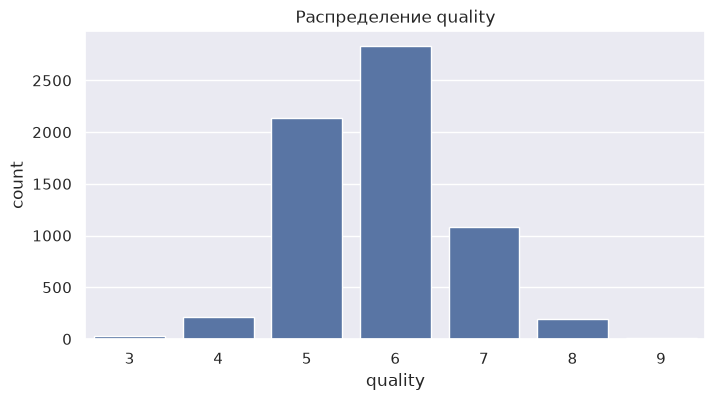

In [7]:
print(data["quality"].value_counts().sort_index())

plt.figure(figsize=(8, 4))
sns.countplot(x="quality", data=data)
plt.title("Распределение quality")
plt.show()

**Выводы по целевой переменной:**
1. `quality` принимает только целые значения от 3 до 9.
2. Распределение очень несбалансированное: почти 77% вин имеют оценку 5 или 6. Очень плохих (3) и очень хороших (8, 9) вин мало, а вин с оценкой 9 всего 5 штук.
3. Для модели это значит, что она хорошо выучит средние вина, а крайние значения будет предсказывать плохо

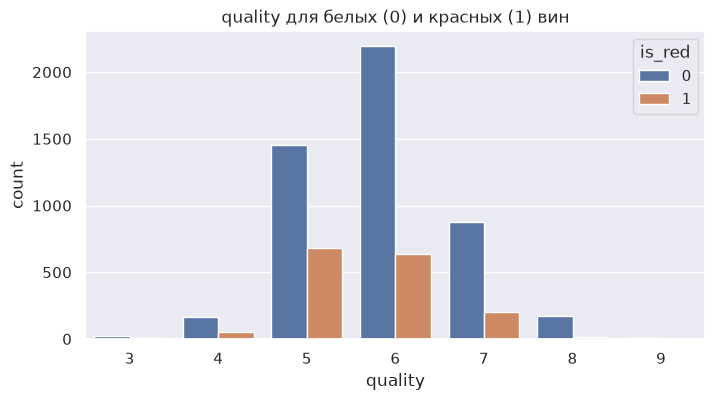

Средний quality у белых: 5.878
Средний quality у красных: 5.636


In [8]:
plt.figure(figsize=(8, 4))
sns.countplot(x="quality", hue="is_red", data=data)
plt.title("quality для белых (0) и красных (1) вин")
plt.show()

print("Средний quality у белых:", round(white["quality"].mean(), 3))
print("Средний quality у красных:", round(red["quality"].mean(), 3))

Распределения оценок у красных и белых вин похожи, белые в среднем оценены чуть выше. Сам по себе тип вина
почти не влияет на оценку

### Распределения признаков

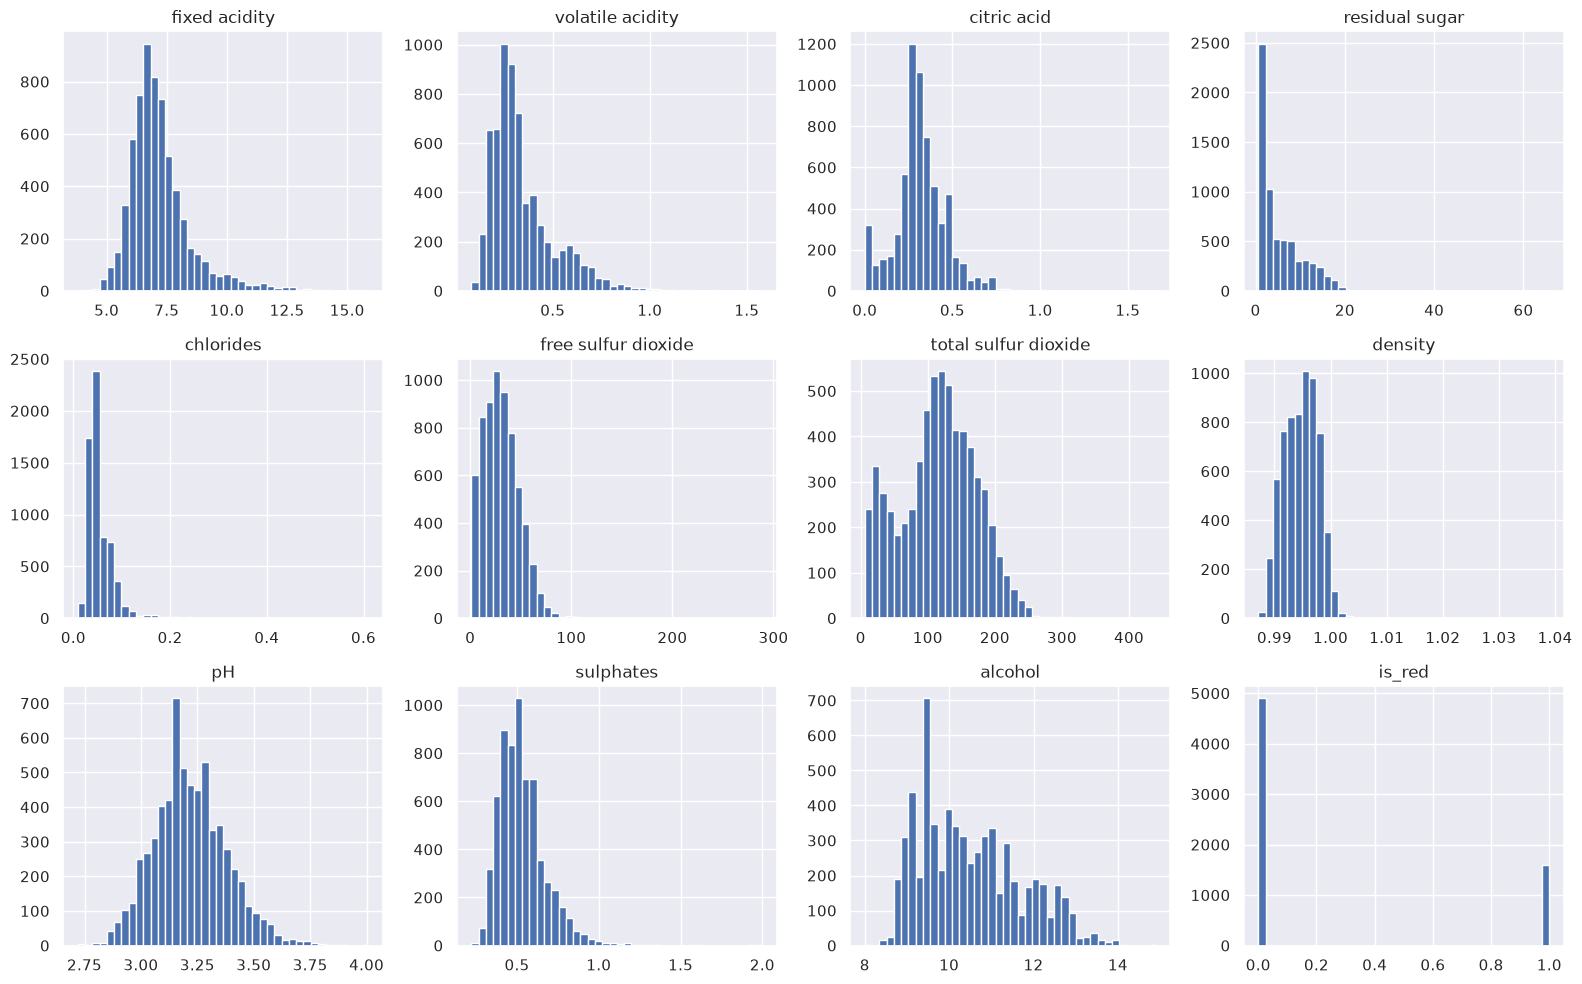

In [ ]:
# список всех признаков
features = list(data.columns)
features.remove("quality")

fig, axs = plt.subplots(3, 4, figsize=(16, 10))

# превращаем сетку 3x4 в обычный список из 12 графиков,
axs = axs.flatten()

# для каждого признака рисуем гистограмму на своём графике
for i in range(len(features)):
    # гистограмма: весь диапазон значений признака делится на 40 интервалов (bins),
    # сколько вин попало в этот интервал
    axs[i].hist(data[features[i]], bins=40)
    # подписываем график названием признака
    axs[i].set_title(features[i])

# автоматически раздвигаем графики, чтобы подписи не налезали друг на друга
plt.tight_layout()
plt.show()

Многие признаки (`residual sugar`, `chlorides`, `free sulfur dioxide`, `sulphates`) имеют длинный хвост вправо -
большинство значений маленькие, но есть редкие очень большие. Для деревьев это не проблема,
потому что они разбивают признак по порогам и им неважен масштаб. Для линейной регрессии выбросы могут немного
испортить коэффициенты. `total sulfur dioxide` имеет два горб - это как раз красные (меньше SO₂) и белые (больше SO₂) вина.

### Корреляции

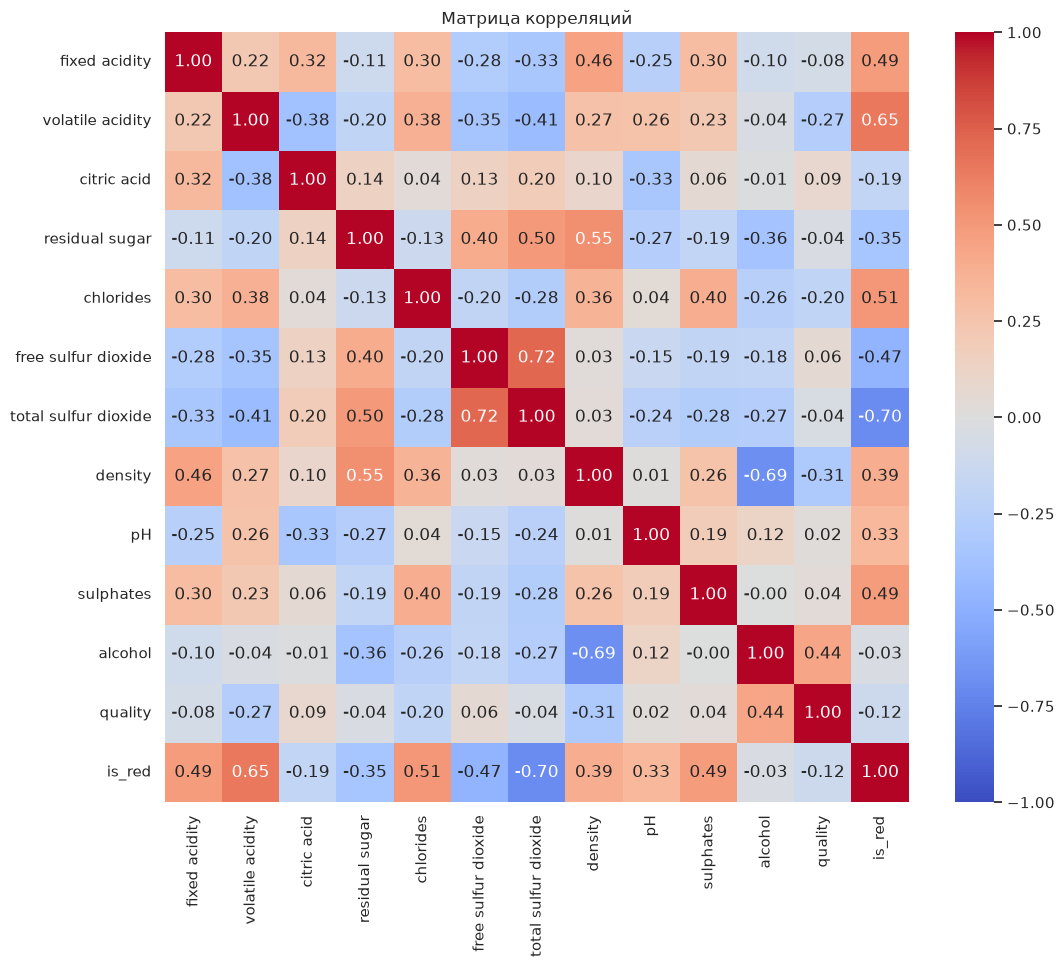

In [10]:
plt.figure(figsize=(12, 10))
sns.heatmap(data.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Матрица корреляций")
plt.show()

alcohol                 0.444319
citric acid             0.085532
free sulfur dioxide     0.055463
sulphates               0.038485
pH                      0.019506
residual sugar         -0.036980
total sulfur dioxide   -0.041385
fixed acidity          -0.076743
is_red                 -0.119323
chlorides              -0.200666
volatile acidity       -0.265699
density                -0.305858
dtype: float64


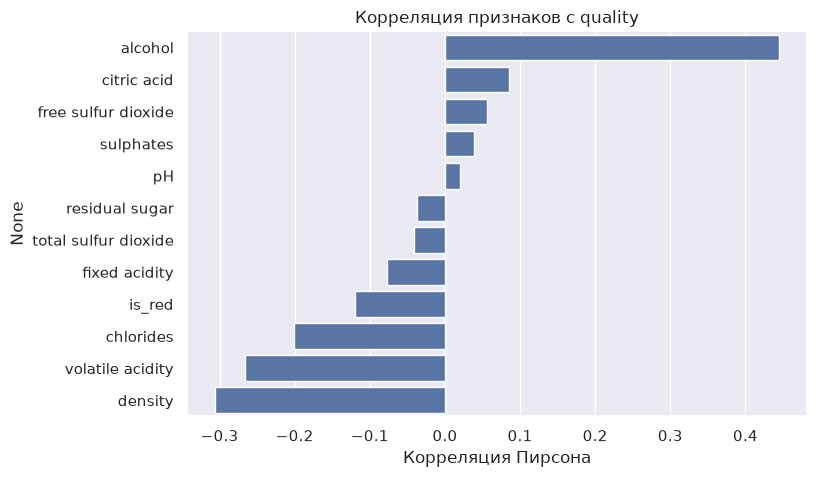

In [11]:
correlations = data[features].corrwith(data["quality"]).sort_values(ascending=False)
print(correlations)

plt.figure(figsize=(8, 5))
sns.barplot(x=correlations.values, y=correlations.index)
plt.title("Корреляция признаков с quality")
plt.xlabel("Корреляция Пирсона")
plt.show()

**Выводы по корреляциям:**

1. `alcohol` сильнее всего связан с качеством (корреляция около +0.44). То есть более крепкие вина эксперты в среднем оценивают выше.
2. `density` связан с качеством отрицательно (около −0.31). Но плотность почти полностью определяется алкоголем и сахаром
  (корреляция `density` и `alcohol` около −0.69: спирт легче воды).
3. `volatile acidity` отрицательно связана с качеством (около −0.27). Летучая кислотность — это в основном уксусная кислота, это реальный дефект вина, и признак полезен.
4. `chlorides` (соль) тоже связаны отрицательно (около −0.20).
5. Остальные признаки (`pH`, `sulphates`, `residual sugar`, `fixed acidity`, `citric acid`) почти не коррелируют с качеством.
  Но корреляция Пирсона показывает только линейную связь. Связь может быть нелинейной или проявляться только вместе
  с другими признаками (например, только для красных вин). Поэтому выкидывать эти признаки я не будем.
6. Все корреляции с target небольшие (максимум 0.44). Значит, ни один признак по отдельности хорошо качество не предсказывает,
  и ждать очень маленькой ошибки не стоит. Оценка эксперта — субъективная, её не получится полностью объяснить химией.

Сильно связаны между собой `free sulfur dioxide` и `total sulfur dioxide` (0.72),
`density` и `alcohol` (−0.69), `density` и `residual sugar` (0.55), а также `is_red` и `total sulfur dioxide` (−0.70).
Для линейной регрессии это значит, что коэффициенты у этих признаков могут быть нестабильными и их трудно интерпретировать
по отдельности. На качество предсказания это влияет мало.

Посмотрим, как выглядит зависимость quality от самых связанных признаков.

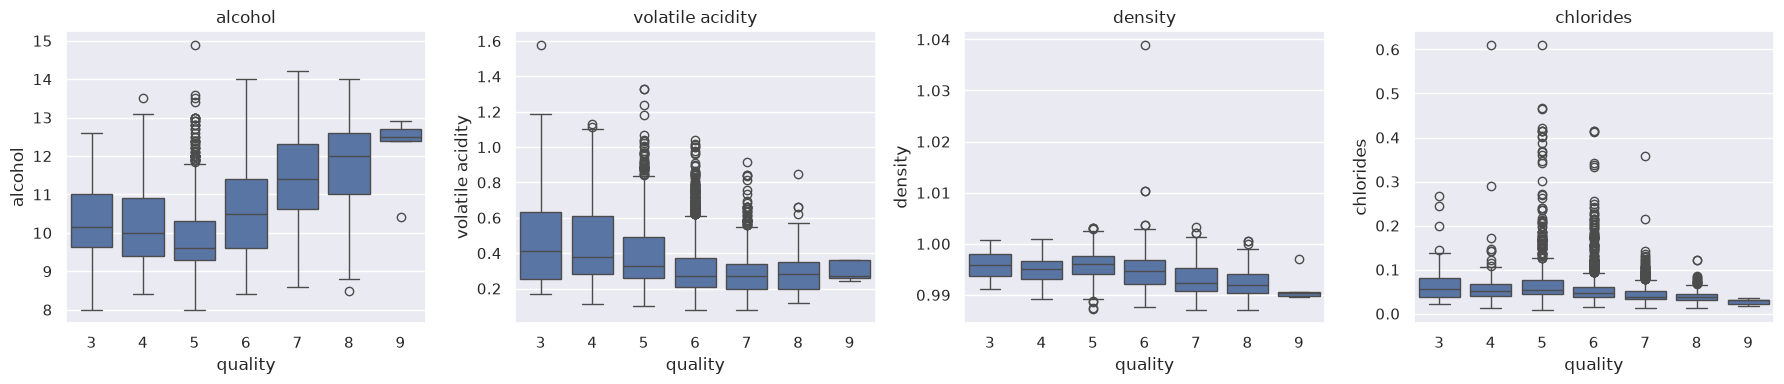

In [12]:
fig, axs = plt.subplots(1, 4, figsize=(18, 4))
for i, feature in enumerate(["alcohol", "volatile acidity", "density", "chlorides"]):
    sns.boxplot(x="quality", y=feature, data=data, ax=axs[i])
    axs[i].set_title(feature)
plt.tight_layout()
plt.show()

**Выводы по графикам:**
- Для `alcohol` : начиная с quality = 5, чем выше оценка, тем больше медиана алкоголя. У вин с оценкой 3–4 алкоголя не меньше, чем у вин с оценкой 5. Плохо для линейной регрессии.
- Для `volatile acidity`: чем выше качество, тем меньше летучих кислот. Сильнее всего это видно на плохих винах (3–4).
- У `density` в основном повторяется картина алкоголя, но наоборот
- Ящики для соседних оценок сильно перекрываются. Это значит, что вина с оценкой 5 и 6 по химическому составу очень похожи, и модели будет трудно их различить.

## 2. Подготовка выборок

Разделяем данные на обучающую (80%) и тестовую (20%) части.

- В тест попадает около 1300 вин, этого достаточно, чтобы оценка метрики была
  устойчивой, и при этом для обучения остаётся около 5200 вин.
- **Способ:** случайное разбиение со стратификацией по `quality` (`stratify=y`). Так как классы редкие (оценки 3, 8 и 9),
  при обычном случайном разбиении могло бы случиться так, что, например, все вина с оценкой 9 попали бы в train, и в тесте
  их бы не было (или наоборот). Стратификация сохраняет одинаковые доли каждой оценки в train и test.
  Данные не зависят от времени, поэтому перемешивать их можно.
- **random_state = 42** зафиксирован, чтобы при каждом запуске разбиение было одинаковым и результат можно было воспроизвести.

если пробовать разные модели и параметры
и каждый раз смотреть на результат на тесте, выбирая лучший, то мы фактически будем подгонять решение под тестовую выборку.
Тогда тест перестанет быть новыми данными, и оценка качества станет слишком оптимистичной. Это переобучение на тест.
Поэтому все решения принимаем по кросс-валидации на обучающей выборке, а на тест смотрю только в конце для финальной оценки.

In [ ]:
from sklearn.model_selection import train_test_split

# признаки
X = data.drop(columns=["quality"])
# целевая переменная
y = data["quality"]

# перемешиваем строки и делим их на 2 части: 80% для обучения и 20% для теста
# stratify=y — делаем так, чтобы в обучающей и тестовой выборках было примерно одинаковое распределение классов
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (5197, 12)
Test: (1300, 12)


In [14]:
# проверим, что доли оценок в train и test почти одинаковые
check = pd.DataFrame({
    "train": y_train.value_counts(normalize=True).sort_index(),
    "test": y_test.value_counts(normalize=True).sort_index()
})
check.round(3)

,train,test
quality,,
3,0.005,0.005
4,0.033,0.033
5,0.329,0.329
6,0.437,0.436
7,0.166,0.166
8,0.030,0.030
9,0.001,0.001


## 3. Метрики

Функция, которая считает обе метрики, чтобы все модели оценивались одинаково.

$$MAE = \frac{1}{n}\sum_{i=1}^{n} |y_i - \hat{y}_i| \qquad RMSE = \sqrt{\frac{1}{n}\sum_{i=1}^{n} (y_i - \hat{y}_i)^2}$$

1. **MAE** показывает, на сколько баллов в среднем модель ошибается. Все ошибки входят с одинаковым весом.
2. **RMSE** — корень из средней квадратичной ошибки. Она тоже измеряется в баллах quality, но ошибки перед усреднением
  возводятся в квадрат. Сильнее реагирует на ошибки, чем MAE из-за квадрата.Поэтому несколько сильных промахов заметно увеличивают RMSE,
  а в MAE они весят пропорционально своей величине.
3. **Почему MAE и RMSE могут сильно отличаться:** всегда RMSE ≥ MAE. Если все ошибки примерно одинаковые, они почти равны.
  Если же модель в основном ошибается немного, но иногда сильно промахивается, RMSE будет заметно больше MAE.
  Так что разница между ними показывает, насколько неравномерные ошибки у модели.
  Для нашей задачи это важно: модель, скорее всего, будет сильно ошибаться на редких винах с оценками 3, 4, 8, 9.

In [15]:
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

def get_metrics(y_true, y_pred):
    rmse = root_mean_squared_error(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    return rmse, mae

# сюда буду складывать результаты всех моделей на тесте
results = []

## 4. Baseline

В качестве baseline предсказываем 1 константу для всех объектов.

Основная метрика - RMSE, а RMSE минимизируется тогда же, когда и MSE.
Если предсказывать константу $c$, то $MSE(c) = \frac{1}{n}\sum (y_i - c)^2$. Берём производную по $c$ и приравниваем к нулю:
$-\frac{2}{n}\sum (y_i - c) = 0$, откуда $c = \frac{1}{n}\sum y_i$, то есть среднее.

среднее считаем только по train

In [16]:
best_constant = y_train.mean()
print("Среднее quality на train:", round(best_constant, 4))
print("Медиана quality на train:", y_train.median())

y_pred_baseline = np.ones(len(y_test)) * best_constant
rmse, mae = get_metrics(y_test, y_pred_baseline)
print("Baseline (среднее): RMSE = %.4f, MAE = %.4f" % (rmse, mae))

# для сравнения посмотрим и на медиану
rmse_med, mae_med = get_metrics(y_test, np.ones(len(y_test)) * y_train.median())
print("Константа-медиана:  RMSE = %.4f, MAE = %.4f" % (rmse_med, mae_med))

results.append(["Baseline", rmse, mae])

Среднее quality на train: 5.8182
Медиана quality на train: 6.0
Baseline (среднее): RMSE = 0.8738, MAE = 0.6861
Константа-медиана:  RMSE = 0.8923, MAE = 0.6377


Как и ожидалось, среднее даёт меньший RMSE, а медиана — меньший MAE. Baseline по RMSE получился около 0.87 —
это фактически стандартное отклонение quality. Любая полезная модель должна давать RMSE меньше этого числа.

## 5. Модели

### 5.1 Линейная регрессия

Модель: $a(x) = w_0 + w_1 x_1 + \dots + w_d x_d$. Сначала обучаем её на исходных признаках.

In [ ]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
# подобрать веса по train
lin_reg.fit(X_train, y_train)

y_pred_train = lin_reg.predict(X_train)
y_pred_lr = lin_reg.predict(X_test)

print("Train RMSE = %.4f" % root_mean_squared_error(y_train, y_pred_train))
print("Test  RMSE = %.4f" % root_mean_squared_error(y_test, y_pred_lr))

Train RMSE = 0.7337
Test  RMSE = 0.7280


In [18]:
coefs = pd.Series(lin_reg.coef_, index=X_train.columns)
print("Коэффициенты без масштабирования:")
print(coefs.sort_values())

Коэффициенты без масштабирования:
density                -107.254294
volatile acidity         -1.461996
chlorides                -0.635322
citric acid              -0.092857
total sulfur dioxide     -0.001602
free sulfur dioxide       0.004882
residual sugar            0.064502
fixed acidity             0.087201
alcohol                   0.215202
is_red                    0.308885
pH                        0.548259
sulphates                 0.744676
dtype: float64


Если смотреть на коэффициенты без масштабирования, получается, что самый важный признак — `density` с огромным
коэффициентом (около −107), а `alcohol` (≈0.2) как будто влияет слабее, чем `sulphates` или `pH`. Но это неправильный вывод: `density` меняется в очень узком диапазоне (стандартное отклонение
около 0.003), поэтому коэффициент должен быть огромным, чтобы изменения плотности вообще влияли на ответ.
Коэффициент показывает, на сколько изменится предсказание, если признак изменится на 1 единицу, а 1 г/см³ для плотности -
это оч большое изменение. Поэтому сравнивать коэффициенты у признаков в разных масштабах напрямую нельзя.

Чтобы сравнивать, нужно привести признаки к одному масштабу с помощью `StandardScaler`: из каждого признака вычитается
среднее и делится на стандартное отклонение. Тогда коэффициент показывает, на сколько изменится quality, если признак
изменится на 1 стандартное отклонение - такие коэффициенты уже можно сравнивать между собой.

In [19]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

lr_pipeline = Pipeline([
    ("scaling", StandardScaler()),
    ("regression", LinearRegression())
])
lr_pipeline.fit(X_train, y_train)

y_pred_train = lr_pipeline.predict(X_train)
y_pred_lr = lr_pipeline.predict(X_test)

print("Train RMSE = %.4f" % root_mean_squared_error(y_train, y_pred_train))
print("Test  RMSE = %.4f" % root_mean_squared_error(y_test, y_pred_lr))

Train RMSE = 0.7337
Test  RMSE = 0.7280


Метрика не изменилась. Масштабирование здесь нужно для интерпретации коэффициентов.

Ошибка на train и на test почти одинаковая - модель не переобучилась. Скорее она необучаемая

density                -0.322959
volatile acidity       -0.242319
total sulfur dioxide   -0.090906
chlorides              -0.021916
citric acid            -0.013599
free sulfur dioxide     0.086140
pH                      0.088102
sulphates               0.109287
fixed acidity           0.112144
is_red                  0.133536
alcohol                 0.255823
residual sugar          0.308646
dtype: float64


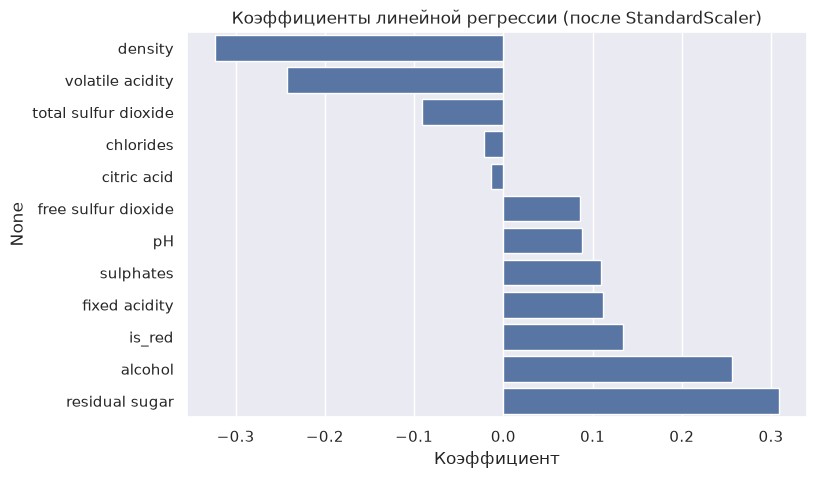

In [20]:
lr_coefs = pd.Series(lr_pipeline.named_steps["regression"].coef_, index=X_train.columns)
lr_coefs = lr_coefs.sort_values()
print(lr_coefs)

plt.figure(figsize=(8, 5))
sns.barplot(x=lr_coefs.values, y=lr_coefs.index)
plt.title("Коэффициенты линейной регрессии (после StandardScaler)")
plt.xlabel("Коэффициент")
plt.show()

In [21]:
rmse, mae = get_metrics(y_test, y_pred_lr)
print("Linear Regression: RMSE = %.4f, MAE = %.4f" % (rmse, mae))
results.append(["Linear Regression", rmse, mae])

Linear Regression: RMSE = 0.7280, MAE = 0.5678


**Анализ линейной регрессии:**

1. RMSE около 0.73 — лучше baseline (0.87). Но порог 0.70 линейная модель не проходит.
2. Самые большие по модулю коэффициенты (после масштабирования): `density` (отрицательный), `residual sugar` и `alcohol`
  (положительные), `volatile acidity` (отрицательный).
3. Знаки `alcohol` (+) и `volatile acidity` (−) совпадают с выводами из EDA.
4. А вот `density` и `residual sugar` в EDA были почти бесполезны.Поэтому такие
  коэффициенты нельзя читать как "сахар повышает качество".
5. Коэффициенты линейной модели можно интерпретировать только с осторожностью - если признаки сильно коррелируют, то вес размазывается между ними непредсказуемо.

### 5.2 Random Forest Regressor

Случайный лес - это много решающих деревьев, каждое из которых обучается на случайной подвыборке объектов
(bootstrap). Предсказание - среднее предсказаний всех деревьев.
В классическом случайном лесе ещё на каждом разбиении берётся случайная часть признаков (`max_features`), но в sklearn
у `RandomForestRegressor` по умолчанию `max_features=1.0`, то есть смотрятся все признаки.
Деревья умеют находить нелинейные зависимости и взаимодействия признаков, а масштабирование им не нужно.

Сначала оценим модель кросс-валидацией на train , чтобы не смотреть на тест.

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

# создаём модель случайного леса с 300 деревьями, фиксируем RANDOM_STATE для воспроизводимости
rf = RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1)

# оцениваем только на train с помощью кросс-валидации
cv_scores = cross_val_score(rf, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error")
print("RMSE на фолдах:", np.round(-cv_scores, 4))
print("Средний CV RMSE = %.4f" % np.mean(-cv_scores))

RMSE на фолдах: [0.6456 0.6354 0.618  0.5872 0.6389]
Средний CV RMSE = 0.6250


Для сравнения посчитаю CV и для линейной регрессии на тех же фолдах.

In [23]:
cv_scores_lr = cross_val_score(lr_pipeline, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error")
print("Linear Regression, средний CV RMSE = %.4f" % np.mean(-cv_scores_lr))

Linear Regression, средний CV RMSE = 0.7363


Случайный лес по кросс-валидации заметно лучше линейной регрессии. Теперь обучаю его на всём train и оцениваю на тесте.

In [24]:
rf.fit(X_train, y_train)

y_pred_train = rf.predict(X_train)
y_pred_rf = rf.predict(X_test)

print("Train RMSE = %.4f" % root_mean_squared_error(y_train, y_pred_train))
print("Test  RMSE = %.4f" % root_mean_squared_error(y_test, y_pred_rf))

rmse, mae = get_metrics(y_test, y_pred_rf)
print("Random Forest: RMSE = %.4f, MAE = %.4f" % (rmse, mae))
results.append(["Random Forest", rmse, mae])

Train RMSE = 0.2239
Test  RMSE = 0.6060
Random Forest: RMSE = 0.6060, MAE = 0.4303


Ошибка на train намного меньше, чем на test. Для случайного леса это нормально: каждое дерево строится до конца и почти
запоминает свою подвыборку. Но благодаря усреднению многих разных деревьев ошибка на тесте всё равно хорошая, и
она близка к оценке по кросс-валидации — значит, CV оценил модель честно.

**Feature importance случайного леса.** В sklearn это `feature_importances_` — насколько в среднем уменьшается ошибка (MSE)
при разбиениях по этому признаку, суммарно по всем деревьям (нормировано так, чтобы сумма была 1).

alcohol                 0.248408
volatile acidity        0.131638
free sulfur dioxide     0.087969
sulphates               0.077453
residual sugar          0.075918
total sulfur dioxide    0.072349
pH                      0.069490
chlorides               0.062947
citric acid             0.057778
fixed acidity           0.057644
density                 0.057198
is_red                  0.001206
dtype: float64


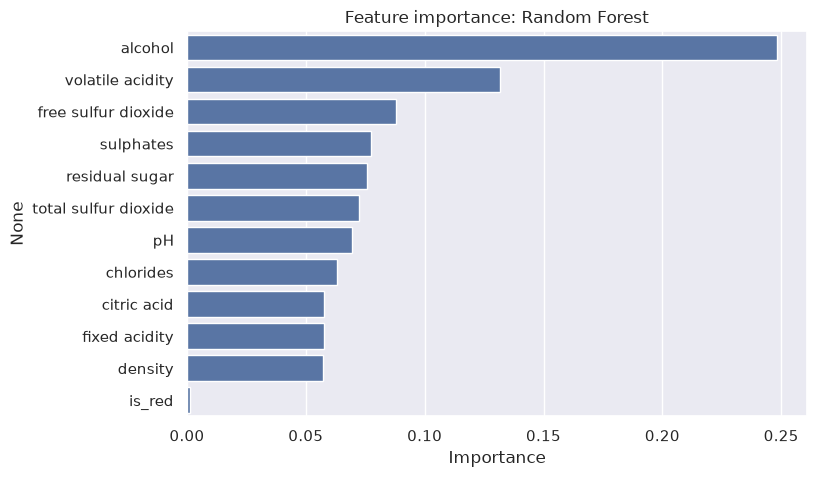

In [25]:
rf_importance = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(rf_importance)

plt.figure(figsize=(8, 5))
sns.barplot(x=rf_importance.values, y=rf_importance.index)
plt.title("Feature importance: Random Forest")
plt.xlabel("Importance")
plt.show()

**Анализ:**
1. Самый важный признак — `alcohol`, с большим отрывом. Это совпадает с EDA (наибольшая корреляция с quality) и с
  линейной регрессией.
2. На втором месте — `volatile acidity`, тоже как в EDA.
3. Дальше идёт `free sulfur dioxide`, а все остальные признаки имеют примерно одинаковую важность (0.06–0.08).
  Интересно, что `free sulfur dioxide` почти не коррелирует с quality линейно, но лес ставит его на третье место. Возможно, связь
  нелинейная: например, при слишком маленьком количестве SO₂ вино хуже сохраняется и портится, а при нормальном и большом уже
  без разницы.
4. `density` у леса почти в самом конце, хотя у линейной регрессии это был самый большой коэффициент, а в EDA — вторая
  по силе корреляция `density` сильно связана с `alcohol`, и лес берёт эту информацию прямо из `alcohol`.
  Ему не нужно "собирать" её из комбинации признаков, как линейной модели.
5. `is_red` — наименее важный признак. Тип вина почти не влияет на оценку, а то, чем красные и белые
  отличаются химически, лес и так видит через другие признаки (например, `total sulfur dioxide`, корреляция с `is_red` −0.70).

Встроенная importance в деревьях имеет недостаток: если два признака сильно коррелируют
(как `alcohol` и `density`), важность делится между ними, и каждый может выглядеть менее важным, чем есть на самом деле.

### 5.3 Gradient Boosting Regressor

Деревья неглубокие и строятся последовательно,
каждое следующее дерево учится исправлять ошибки предыдущих. Ответ - начальное предсказание (среднее quality по train)
плюс
 сумма предсказаний всех деревьев, умноженных на `learning_rate`.

Сначала попробую параметры по умолчанию (100 деревьев глубины 3, learning_rate = 0.1).

In [27]:
from sklearn.ensemble import GradientBoostingRegressor

gb_default = GradientBoostingRegressor(random_state=RANDOM_STATE)
cv_scores = cross_val_score(gb_default, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error")
print("GB по умолчанию, средний CV RMSE = %.4f" % np.mean(-cv_scores))

GB по умолчанию, средний CV RMSE = 0.6853


С параметрами по умолчанию бустинг хуже случайного леса. Скорее всего, 100 деревьев глубины 3 — это слишком мало,
модель недообучена. Попробую несколько вариантов: больше деревьев, глубже деревья и меньше learning_rate
(чтобы каждое дерево делало шаг поменьше и модель меньше переобучалась).

In [ ]:
params_list = [
    # пробуем разные комбинации гиперпараметров
    # n_estimators — количество деревьев, 
    # learning_rate — скорость обучения, 
    # max_depth — максимальная глубина дерева
    {"n_estimators": 100, "learning_rate": 0.1,  "max_depth": 3},
    {"n_estimators": 300, "learning_rate": 0.1,  "max_depth": 3},
    {"n_estimators": 300, "learning_rate": 0.05, "max_depth": 5},
    {"n_estimators": 500, "learning_rate": 0.05, "max_depth": 5},
    {"n_estimators": 500, "learning_rate": 0.05, "max_depth": 7},
]

best_score = 100
best_params = None
# перебираем все комбинации гиперпараметров
for params in params_list:
    model = GradientBoostingRegressor(
        n_estimators=params["n_estimators"],
        learning_rate=params["learning_rate"],
        max_depth=params["max_depth"],
        subsample=0.8,
        random_state=RANDOM_STATE
    )
    scores = cross_val_score(model, X_train, y_train, cv=5, scoring="neg_root_mean_squared_error")
    mean_rmse = np.mean(-scores)
    print(params, "CV RMSE = %.4f" % mean_rmse)
    if mean_rmse < best_score:
        best_score = mean_rmse
        best_params = params

print()
print("Лучшие параметры:", best_params, "CV RMSE = %.4f" % best_score)

{'n_estimators': 100, 'learning_rate': 0.1, 'max_depth': 3} CV RMSE = 0.6844


{'n_estimators': 300, 'learning_rate': 0.1, 'max_depth': 3} CV RMSE = 0.6682


{'n_estimators': 300, 'learning_rate': 0.05, 'max_depth': 5} CV RMSE = 0.6462


{'n_estimators': 500, 'learning_rate': 0.05, 'max_depth': 5} CV RMSE = 0.6385


{'n_estimators': 500, 'learning_rate': 0.05, 'max_depth': 7} CV RMSE = 0.6243

Лучшие параметры: {'n_estimators': 500, 'learning_rate': 0.05, 'max_depth': 7} CV RMSE = 0.6243


`subsample=0.8` значит, что каждое дерево обучается на случайных 80% объектов — это немного уменьшает переобучение. Более глубокие деревья и больше итераций помогают: модель может
уловить более сложные зависимости между признаками (дерево глубины 3 может учесть взаимодействие максимум трёх
признаков, а глубины 7 — намного больше).

Лучший вариант оказался последним в списке (самые глубокие деревья). Можно было бы попробовать ещё глубже,
но стопаемся здесь: улучшение от 5 к 7 уже небольшое

Обучаем бустинг с лучшими параметрами на всём train и оцениваем на тесте.

In [29]:
gb = GradientBoostingRegressor(
    n_estimators=best_params["n_estimators"],
    learning_rate=best_params["learning_rate"],
    max_depth=best_params["max_depth"],
    subsample=0.8,
    random_state=RANDOM_STATE
)
gb.fit(X_train, y_train)

y_pred_train = gb.predict(X_train)
y_pred_gb = gb.predict(X_test)

print("Train RMSE = %.4f" % root_mean_squared_error(y_train, y_pred_train))
print("Test  RMSE = %.4f" % root_mean_squared_error(y_test, y_pred_gb))

rmse, mae = get_metrics(y_test, y_pred_gb)
print("Gradient Boosting: RMSE = %.4f, MAE = %.4f" % (rmse, mae))
results.append(["Gradient Boosting", rmse, mae])

Train RMSE = 0.1442
Test  RMSE = 0.6003
Gradient Boosting: RMSE = 0.6003, MAE = 0.4186


На train ошибка бустинга очень маленькая (модель сильно подстроилась под обучающие данные), но на тесте
результат хороший и близок к оценке по кросс-валидации, так что переобучение не испортило качество на новых данных.

alcohol                 0.224128
volatile acidity        0.123647
free sulfur dioxide     0.089917
total sulfur dioxide    0.080422
residual sugar          0.079216
sulphates               0.077592
density                 0.070684
pH                      0.069962
chlorides               0.065198
fixed acidity           0.060582
citric acid             0.057976
is_red                  0.000676
dtype: float64


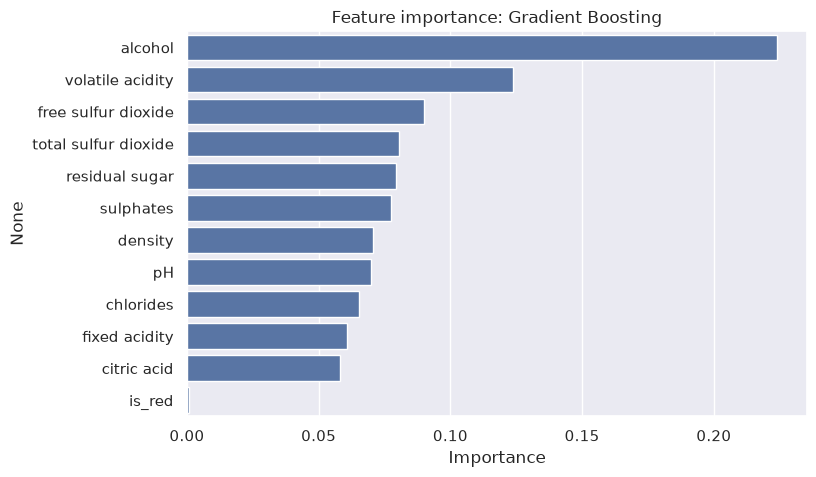

In [30]:
gb_importance = pd.Series(gb.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(gb_importance)

plt.figure(figsize=(8, 5))
sns.barplot(x=gb_importance.values, y=gb_importance.index)
plt.title("Feature importance: Gradient Boosting")
plt.xlabel("Importance")
plt.show()

**Сравнение важности у RF и GB:**
- В обеих моделях `alcohol` - самый важный признак, `volatile acidity` - второй,
  `free sulfur dioxide` - третий. Это совпадает с EDA.
- Значения важностей тоже близки (у `alcohol` 0.25 в лесе и 0.22 в бустинге).
- В середине списка порядок немного отличается: например, `density` в бустинге на 7-м месте, а в лесе на 11-м.
- `is_red` в обеих моделях на последнем месте.

## 6. Сравнение моделей

Все модели обучались на одном и том же train и оценивались на одном и том же test (одно разбиение с `random_state=42`).
Параметры бустинга выбирались по кросс-валидации на train, тест использован только для финальной оценки.

In [31]:
results_table = pd.DataFrame(results, columns=["Модель", "RMSE", "MAE"])
results_table["RMSE"] = results_table["RMSE"].round(4)
results_table["MAE"] = results_table["MAE"].round(4)
results_table

,Модель,RMSE,MAE
0,Baseline,0.8738,0.6861
1,Linear Regression,0.7280,0.5678
2,Random Forest,0.6060,0.4303
3,Gradient Boosting,0.6003,0.4186


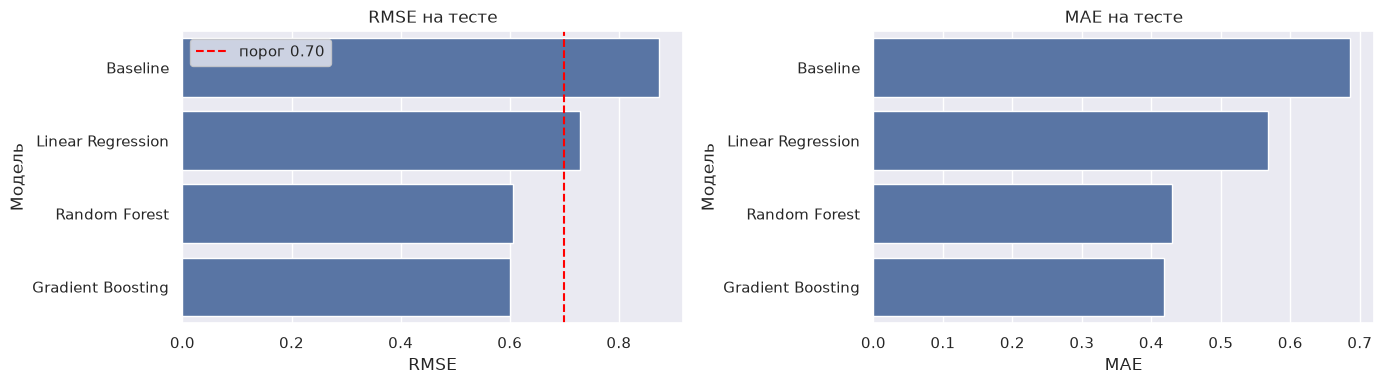

In [32]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(x="RMSE", y="Модель", data=results_table, ax=axs[0])
axs[0].axvline(0.70, color="red", linestyle="--", label="порог 0.70")
axs[0].legend()
axs[0].set_title("RMSE на тесте")
sns.barplot(x="MAE", y="Модель", data=results_table, ax=axs[1])
axs[1].set_title("MAE на тесте")
plt.tight_layout()
plt.show()

**Анализ результатов:**

1. Все 3 модели превзошли baseline и по RMSE, и по MAE. Значит, химические свойства действительно несут информацию о качестве.
2. Линейная регрессия улучшила baseline меньше всех и не прошла порог 0.70. Причина: она может описать только
  линейную зависимость, а в EDA мы видели, что связь нелинейная ,
  а признаки влияют совместно. Ошибки на train и test у неё почти одинаковые - это недообучение, модель слишком простая.
3. Случайный лес и градиентный бустинг - оба проходят порог 0.70 с запасом и намного лучше линейной модели.
  Деревья умеют находить пороги и взаимодействия признаков,
  поэтому нелинейные зависимости из EDA им не мешают.
4. Лучшая модель - Gradient Boosting (RMSE ≈ 0.600), но лес почти такой же (≈ 0.606). По кросс-валидации у них
  тоже почти одинаковый результат (0.624 и 0.625). Механизмы разные:
  лес усредняет много независимых глубоких деревьев (уменьшает разброс), а бустинг строит деревья последовательно,
  каждое исправляет ошибки предыдущих (уменьшает смещение).
5. Важно, что бустинг с параметрами по умолчанию был хуже леса (CV 0.685 против 0.625): 100 деревьев глубины 3 -
  слишком простая модель, она недообучена. Лес же хорошо работает почти без настройки. После увеличения глубины и
  числа деревьев бустинг догнал лес.
6. Ещё одна причина хорошего качества обоих ансамблей - в данных много одинаковых и очень похожих вин.
  Глубокие деревья фактически запоминают такие примеры, и для такого же вина в тесте выдают почти точную оценку.
  Линейная модель так не умеет.
7. У всех моделей RMSE заметно больше MAE (примерно в 1.3–1.4 раза). Это значит, что модели в основном ошибаются
  немного, но на части объектов промахиваются сильно. 

## 7. Feature importance: сравнение всех моделей и связь с EDA

Соберем в одну таблицу:
- модуль корреляции с quality (EDA),
- модуль коэффициентов линейной регрессии после масштабирования,
- importance случайного леса,
- importance бустинга.

Для удобства сравнения разобьем по рангам.

In [33]:
compare = pd.DataFrame({
    "|corr| (EDA)": correlations.abs(),
    "|coef| LR": lr_coefs.abs(),
    "RF": rf_importance,
    "GB": gb_importance
})
compare = compare.sort_values("RF", ascending=False)
compare.round(3)

,|corr| (EDA),|coef| LR,RF,GB
alcohol,0.444,0.256,0.248,0.224
volatile acidity,0.266,0.242,0.132,0.124
free sulfur dioxide,0.055,0.086,0.088,0.090
sulphates,0.038,0.109,0.077,0.078
residual sugar,0.037,0.309,0.076,0.079
total sulfur dioxide,0.041,0.091,0.072,0.080
pH,0.020,0.088,0.069,0.070
chlorides,0.201,0.022,0.063,0.065
citric acid,0.086,0.014,0.058,0.058
fixed acidity,0.077,0.112,0.058,0.061


In [34]:
ranks = compare.rank(ascending=False).astype(int)
ranks

,|corr| (EDA),|coef| LR,RF,GB
alcohol,1,3,1,1
volatile acidity,3,4,2,2
free sulfur dioxide,8,10,3,3
sulphates,10,7,4,6
residual sugar,11,2,5,5
total sulfur dioxide,9,8,6,4
pH,12,9,7,8
chlorides,4,11,8,9
citric acid,6,12,9,11
fixed acidity,7,6,10,10


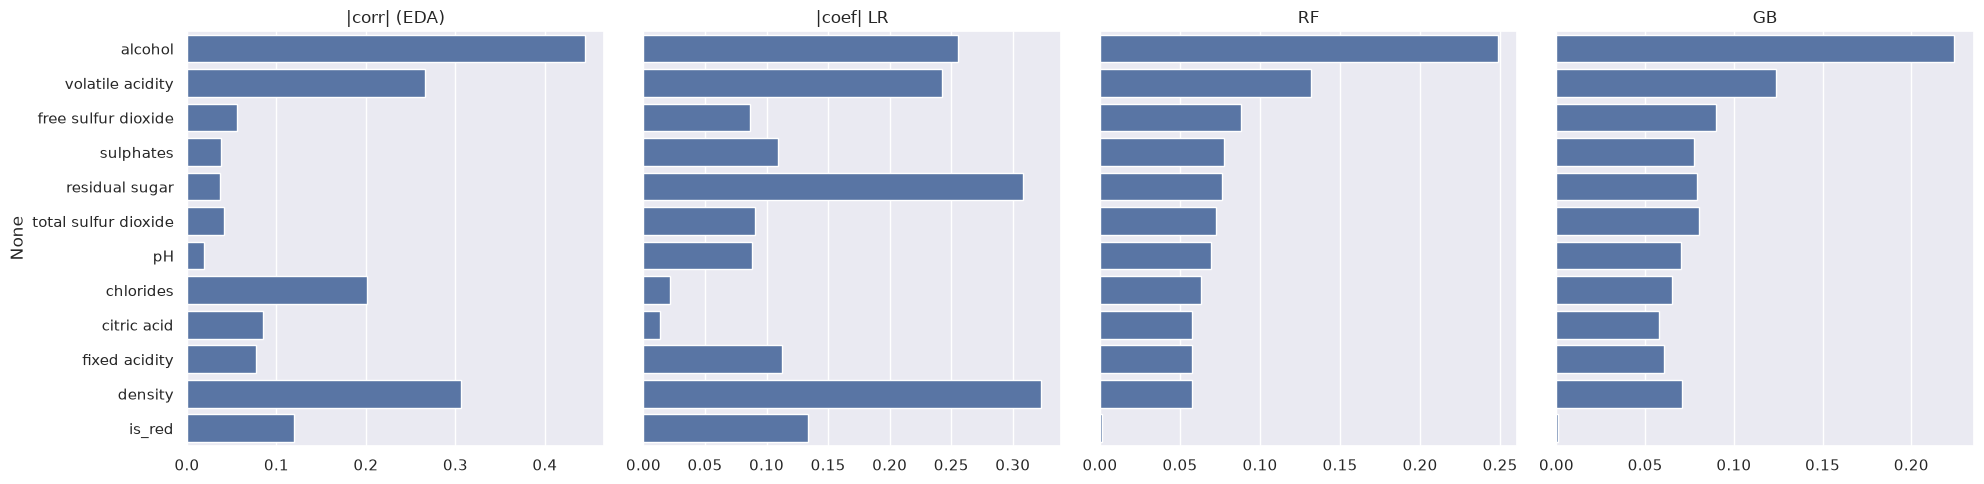

In [35]:
fig, axs = plt.subplots(1, 4, figsize=(20, 5), sharey=True)
for i, col in enumerate(compare.columns):
    sns.barplot(x=compare[col].values, y=compare.index, ax=axs[i])
    axs[i].set_title(col)
plt.tight_layout()
plt.show()

**Выводы:**

1. Наиболее важные признаки - `alcohol` и `volatile acidity`. Они на 1–4 месте во всех 4 столбцах.
2. `density` и `residual sugar`. У линейной регрессии это самые тяжёлые коэффициенты (1 и 2 место),
   у деревьев — в середине или в конце. Это следствие мультиколлинеарности: линейная модель восстанавливает
   нужную зависимость через комбинацию сильно связанных признаков (`density` ≈ функция от `alcohol` и `residual sugar`),
   а дереву достаточно взять `alcohol` напрямую. При этом в EDA у `density` вторая по силе корреляция - но, скорее всего,
   только потому, что она отражает алкоголь.
3. **`free sulfur dioxide`** почти не коррелирует с quality (8 место по корреляции), но у деревьев на 3 месте. Это пример того,
   что корреляция Пирсона видит только линейную связь, а деревья находят нелинейную (пороговую) - мы это проверили выше.
4. **`chlorides`** в EDA на 4 месте, а у моделей в конце списка. Хлоридов больше у красных вин,
   а красные вина в среднем оценены ниже. Похоже, что часть корреляции `chlorides` с quality - это на самом деле разница
   между красными и белыми винами, а модели эту информацию берут из других признаков.
5. **`is_red`** - у деревьев наименее важный признак. его вклад
   просто уже покрыт другими признаками, которые сильно отличаются у красных и белых вин.


По feature importance нельзя утверждать, что признак - причина изменения качества. Feature importance показывает только то, насколько модель использует признак для предсказания, то есть
насколько признак *связан* с target в этих данных. Это корреляция, а не причинность. 

## 8. Анализ ошибок лучшей модели

Лучшая модель по RMSE на тесте — градиентный бустинг (хотя лес почти такой же). Ошибку считаю как
`error = y_true - y_pred` (положительная ошибка — модель занизила оценку, отрицательная — завысила).

In [36]:
errors_df = X_test.copy()
errors_df["quality"] = y_test
errors_df["pred"] = y_pred_gb
errors_df["error"] = errors_df["quality"] - errors_df["pred"]
errors_df["abs_error"] = errors_df["error"].abs()

print(errors_df["error"].describe())

count    1300.000000
mean       -0.040951
std         0.599132
min        -2.753361
25%        -0.325483
50%        -0.021834
75%         0.230354
max         2.365047
Name: error, dtype: float64


### 8.1 Распределение ошибок

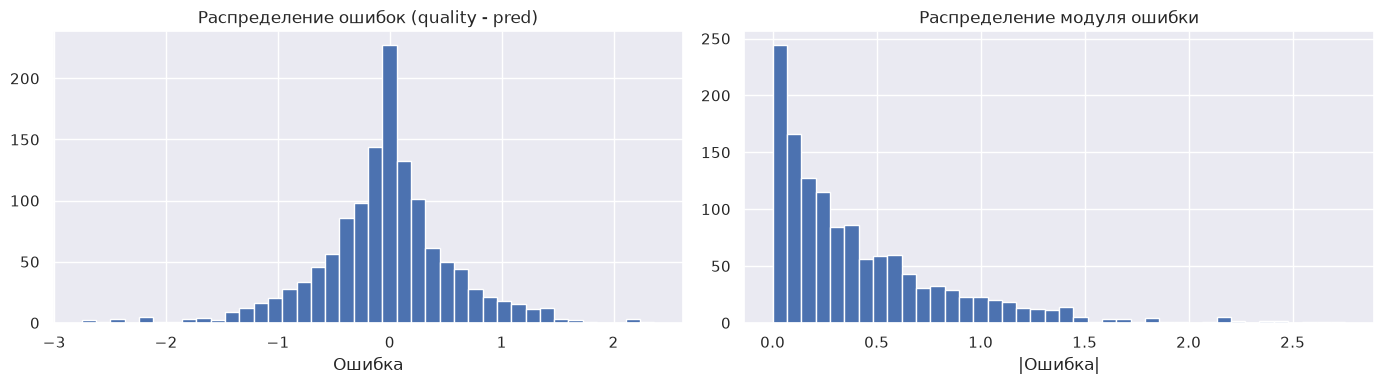

Доля объектов с |ошибкой| < 0.5: 0.685
Доля объектов с |ошибкой| < 1:   0.902
Доля объектов с |ошибкой| >= 2:  0.012


In [37]:
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
axs[0].hist(errors_df["error"], bins=40)
axs[0].set_title("Распределение ошибок (quality - pred)")
axs[0].set_xlabel("Ошибка")

axs[1].hist(errors_df["abs_error"], bins=40)
axs[1].set_title("Распределение модуля ошибки")
axs[1].set_xlabel("|Ошибка|")
plt.tight_layout()
plt.show()

print("Доля объектов с |ошибкой| < 0.5:", round((errors_df["abs_error"] < 0.5).mean(), 3))
print("Доля объектов с |ошибкой| < 1:  ", round((errors_df["abs_error"] < 1).mean(), 3))
print("Доля объектов с |ошибкой| >= 2: ", round((errors_df["abs_error"] >= 2).mean(), 3))

Распределение ошибок симметричное вокруг нуля с острым пиком — большая часть ошибок маленькие. Но есть "хвосты":
небольшое число объектов с ошибкой больше 1.5–2 балла. Как раз они и делают RMSE заметно больше MAE.

### 8.2 Истинные и предсказанные значения

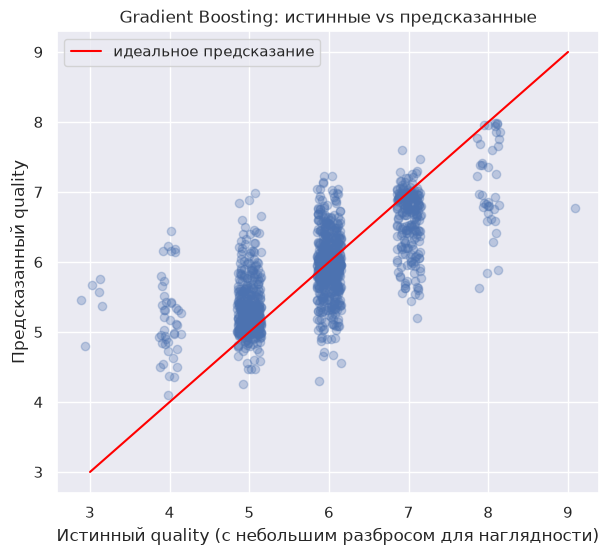

In [38]:
plt.figure(figsize=(7, 6))
plt.scatter(errors_df["quality"] + np.random.uniform(-0.15, 0.15, len(errors_df)), errors_df["pred"], alpha=0.3)
plt.plot([3, 9], [3, 9], color="red", label="идеальное предсказание")
plt.xlabel("Истинный quality (с небольшим разбросом для наглядности)")
plt.ylabel("Предсказанный quality")
plt.title("Gradient Boosting: истинные vs предсказанные")
plt.legend()
plt.show()

Видно, что предсказания сжаты к середине: для вин с оценкой 3–4 модель предсказывает примерно 5,
а для вин с оценкой 8–9 — около 7. Точки для крайних оценок лежат далеко от красной линии:
плохие вина модель переоценивает, а хорошие — недооценивает. Предсказания почти никогда не выходят за отрезок [4, 8].

### 8.3 Качество для разных значений quality

In [39]:
by_quality = []
for q in sorted(errors_df["quality"].unique()):
    part = errors_df[errors_df["quality"] == q]
    rmse_q, mae_q = get_metrics(part["quality"], part["pred"])
    by_quality.append([q, len(part), round(part["pred"].mean(), 3), round(part["error"].mean(), 3), round(rmse_q, 3), round(mae_q, 3)])

by_quality = pd.DataFrame(by_quality, columns=["quality", "кол-во в тесте", "средний pred", "средняя ошибка", "RMSE", "MAE"])
by_quality

,quality,кол-во в тесте,средний pred,средняя ошибка,RMSE,MAE
0,3,6,5.440,-2.440,2.459,2.440
1,4,43,5.198,-1.198,1.319,1.198
2,5,428,5.326,-0.326,0.518,0.366
3,6,567,5.951,0.049,0.445,0.332
4,7,216,6.591,0.409,0.607,0.447
5,8,39,7.126,0.874,1.081,0.874
6,9,1,6.769,2.231,2.231,2.231


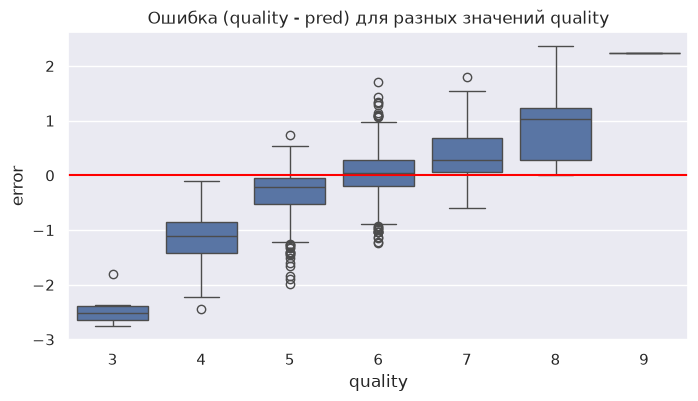

In [40]:
plt.figure(figsize=(8, 4))
sns.boxplot(x="quality", y="error", data=errors_df)
plt.axhline(0, color="red")
plt.title("Ошибка (quality - pred) для разных значений quality")
plt.show()

**Модель работает очень неодинаково для разных оценок:**
- Для вин с оценками 5 и 6 ошибка маленькая, средняя ошибка близка к нулю.
- Для оценок 3, 4 средняя ошибка отрицательная (модель завышает), для 8, 9 — положительная (занижает). RMSE для
  крайних оценок в несколько раз больше, чем для 5–6.

**Модель плохо работает с высокими или низками оценками, потому что**
1. Вин с оценкой 3 в train всего около 24, с оценкой 9 - 4.
2. **Модель минимизирует среднюю ошибку по всем объектам.** Так как ~77% вин — это 5 и 6, модели выгоднее хорошо
  предсказывать их, а редкие вина вносят в общую ошибку мало. Поэтому "безопаснее" предсказывать ближе к середине.
3. В каждом листе дерева ответ - среднее по объектам, которые туда попали. Для редкого
  вина в том же листе почти всегда окажутся и средние вина с похожим составом, поэтому ответ сдвигается к 5–6.
  Бустинг к тому же начинает с предсказания среднего (≈5.8) и маленькими шагами двигается от него -
  для редких объектов этих шагов не хватает, чтобы дойти до 3 или 9.
4. По boxplot из EDA видно, что признаки у вин 3–4 и 5, а также 7–8 и 6 сильно пересекаются.

### 8.4 Объекты с наибольшими ошибками

In [41]:
worst = errors_df.sort_values("abs_error", ascending=False).head(10)
worst[["is_red", "alcohol", "volatile acidity", "free sulfur dioxide", "sulphates", "density", "quality", "pred", "error"]].round(3)

,is_red,alcohol,volatile acidity,free sulfur dioxide,sulphates,density,quality,pred,error
1374,1,9.8,0.815,16.0,0.51,0.995,3,5.753,-2.753
1850,0,9.8,0.260,41.0,0.50,0.998,3,5.672,-2.672
3287,0,9.4,0.250,118.5,0.63,0.995,3,5.573,-2.573
2339,0,12.6,0.390,5.0,0.37,0.992,3,5.463,-2.463
6107,0,11.5,0.260,75.0,0.38,0.990,4,6.438,-2.438
1469,1,9.7,0.980,20.0,0.55,0.997,3,5.370,-2.370
3005,0,10.5,0.220,12.0,0.38,0.994,8,5.635,2.365
2426,0,12.5,0.240,27.0,0.48,0.991,9,6.769,2.231
5369,0,12.0,0.270,15.0,0.65,0.991,4,6.223,-2.223
3715,0,11.7,0.200,19.0,0.37,0.990,4,6.183,-2.183


Для сравнения посмотрю на средние значения важных признаков у вин с каждой оценкой в train:

In [42]:
train_df = X_train.copy()
train_df["quality"] = y_train
train_df.groupby("quality")[["alcohol", "volatile acidity", "free sulfur dioxide", "sulphates", "density"]].mean().round(3)

,alcohol,volatile acidity,free sulfur dioxide,sulphates,density
quality,,,,,
3,10.252,0.521,40.333,0.505,0.996
4,10.163,0.450,20.509,0.501,0.995
5,9.830,0.392,30.354,0.527,0.996
6,10.568,0.314,31.103,0.534,0.995
7,11.365,0.288,30.375,0.547,0.993
8,11.634,0.284,35.123,0.503,0.992
9,12.100,0.312,35.000,0.462,0.992


**Разбор нескольких сильных ошибок** (номера — индексы строк в таблице выше):

Почти все самые большие ошибки — на винах с редкими оценками 3, 4, 8, 9. Среди 10 худших нет ни одного вина с оценкой 5–7.

- **Вина 1850 и 3287 (белые, quality = 3, предсказано ≈5.6).** Алкоголь 9.4–9.8% и `volatile acidity` ≈0.25 —
  это типичные значения для вина с оценкой 5 (см. таблицу средних: у оценки 5 алкоголь 9.8, у оценки 3 —
  `volatile acidity` в среднем 0.52). По главным признакам эти вина выглядят как обычные средние, поэтому модель ставит им
  среднюю оценку. У вина 3287 очень много свободного SO₂ (118.5, почти в 4 раза больше среднего) — возможно, вино "пересушено"
  консервантом, но таких примеров в train слишком мало, чтобы модель это выучила.
- **Вино 2339 (белое, quality = 3, предсказано ≈5.5).** Здесь признаки противоречат друг другу: алкоголь 12.6% —
  как у вин с оценками 8–9, но свободного SO₂ всего 5 (очень мало, вино могло окислиться). Модель "усреднила" эти сигналы
  и выдала что-то посередине.
- **Вина 5369 и 3715 (quality = 4, предсказано ≈6.2).** Алкоголь 11.7–12% и низкая `volatile acidity` (0.20–0.27) —
  по двум главным признакам это скорее хорошее вино. Модель сильнее всего опирается на `alcohol`, поэтому завышает оценку.
- **Вино 3005 (quality = 8, предсказано ≈5.6) и вино 2426 (quality = 9, предсказано ≈6.8).** У вина 3005 алкоголь
  10.5% — ниже среднего для хороших вин (≈11.6). У вина 2426 алкоголь высокий (12.5%), и модель подняла оценку,
  но только до 6.8: вин с оценкой 9 в train всего 4, и модель практически никогда не предсказывает выше 8.
- **Вино 1374 (красное, quality = 3, предсказано ≈5.8).** У него очень высокая `volatile acidity` (0.815), что должно
  говорить о плохом вине. Но у красных вин летучая кислотность в целом выше, чем у белых (корреляция `is_red` и
  `volatile acidity` 0.65). Среди всех красных вин с `volatile acidity` ≥ 0.8 только 6 имеют оценку 3, а 55 — оценку 5.
  То есть для модели такое значение скорее говорит "вино на 5", поэтому она не "поверила" этому признаку.

Общая причина: `quality` — это субъективная оценка экспертов, и наши 12 признаков описывают вино не полностью
(нет сорта винограда, года, региона, цены, данных о вкусе и аромате). Поэтому часть ошибок — это неустранимый шум,
и с этими признаками сильно уменьшить ошибку на таких объектах вряд ли получится.

### 8.5 Проверка влияния дубликатов

Как я писал в EDA, в данных много одинаковых строк, и одно и то же вино может попасть и в train, и в test.
Проверю, насколько это влияет на метрику: разделю тестовые объекты на те, у которых точно такой же набор признаков
есть в train, и на "новые".

In [43]:
train_rows = set()
for row in X_train.values:
    train_rows.add(tuple(row))

in_train = []
for row in X_test.values:
    in_train.append(tuple(row) in train_rows)
in_train = np.array(in_train)

print("Объектов теста, которые есть в train:", in_train.sum(), "из", len(in_train))
print()

all_preds = {
    "Baseline": y_pred_baseline,
    "Linear Regression": y_pred_lr,
    "Random Forest": y_pred_rf,
    "Gradient Boosting": y_pred_gb
}

dup_check = []
for name in all_preds:
    pred = all_preds[name]
    rmse_all, mae_all = get_metrics(y_test, pred)
    rmse_seen, mae_seen = get_metrics(y_test[in_train], pred[in_train])
    rmse_new, mae_new = get_metrics(y_test[~in_train], pred[~in_train])
    dup_check.append([name, round(rmse_all, 4), round(rmse_seen, 4), round(rmse_new, 4)])

dup_check = pd.DataFrame(dup_check, columns=["Модель", "RMSE весь тест", "RMSE 'знакомые'", "RMSE новые"])
dup_check

Объектов теста, которые есть в train: 357 из 1300



,Модель,RMSE весь тест,RMSE 'знакомые',RMSE новые
0,Baseline,0.8738,0.8319,0.8891
1,Linear Regression,0.7280,0.7108,0.7344
2,Random Forest,0.6060,0.2207,0.6985
3,Gradient Boosting,0.6003,0.1559,0.6983


**Это важный результат.** Около 27% тестовых вин точно такие же, как какие-то вина из train.
На таких "знакомых" объектах ансамбли ошибаются очень мало — они их фактически помнят.
Линейная регрессия и baseline так не умеют, поэтому у них ошибка на "знакомых" и новых объектах почти одинаковая.

На **полностью новых** винах RMSE у леса и бустинга около 0.70 — то есть ровно на границе порога. Значит:
- модели действительно извлекают закономерности из признаков (на новых винах они всё равно намного лучше baseline 0.87
  и лучше линейной регрессии), а не только запоминают дубликаты;
- но общая метрика на тесте (≈0.60) **оптимистична**: часть качества получена за счёт повторяющихся вин. Если бы в скрытом
  тесте были только вина, которых нет в обучающих данных, ошибка была бы ближе к 0.70.

Я оставил основной эксперимент на исходных данных (с дубликатами), так как это стандартная версия датасета, но при
интерпретации результата нужно помнить про эту поправку. Альтернатива — удалить дубликаты до разбиения
(`data.drop_duplicates()`), тогда оценка на тесте была бы честнее, но и ниже.

## 9. Выводы

1. **Данные.** 6497 вин (красные + белые), 11 химических признаков + тип вина, пропусков нет. Целевая переменная
   `quality` сильно несбалансирована: в основном оценки 5–6. Сильнее всего с качеством связаны `alcohol` (+)
   и `volatile acidity` (−), остальные признаки связаны слабо или нелинейно. Есть мультиколлинеарность
   (`density` – `alcohol` – `residual sugar`, два вида SO₂) и около 18% дубликатов.
2. **Разбиение.** 80/20 со стратификацией по `quality`, `random_state=42`. Параметры выбирались по кросс-валидации
   на train, тест использован только для финальной оценки.
3. **Baseline** — среднее quality по train (оптимальная константа для RMSE), RMSE ≈ 0.87.
4. **Модели.** Все модели лучше baseline. Линейная регрессия (RMSE ≈ 0.73) недообучается, так как зависимость нелинейная,
   и порог 0.70 не проходит. Лучшая модель — **Gradient Boosting** (RMSE ≈ 0.600, MAE ≈ 0.419) после подбора параметров
   по кросс-валидации, **Random Forest** практически такой же (RMSE ≈ 0.606). Порог 0.70 оба проходят.
5. **Важность признаков.** Все модели и EDA сходятся в том, что главные признаки — `alcohol` и `volatile acidity`.
   Расхождения (у `density`, `residual sugar`, `free sulfur dioxide`, `chlorides`) объясняются мультиколлинеарностью
   и нелинейными связями. Feature importance не говорит о причинности.
6. **Ошибки.** Модель хорошо предсказывает частые оценки 5–6 и плохо — редкие крайние оценки (3–4 и 8–9):
   предсказания стягиваются к середине. Причины — мало примеров редких оценок, минимизация средней ошибки,
   усреднение в листьях деревьев и то, что химический состав не полностью объясняет субъективную оценку экспертов.
7. **Дубликаты.** Часть тестовых вин совпадает с винами из train, и ансамбли на них почти не ошибаются. На полностью новых
   винах RMSE ≈ 0.70, поэтому итоговая метрика немного оптимистична — это нужно учитывать.